In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import os

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Move up to project root (from notebooks/ to root)
os.chdir("..")

# 2. Add root to path so we can import our modules
sys.path.append(str(Path.cwd()))
from src.data.loader import load_raw
from src.features.build_features import build_features

In [3]:
# Load raw data and feature engineering
df = load_raw()
df = build_features(df)

df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

print(f"Dataset shape: {df.shape}")
print(f"Overall 30-day readmission rate: {df['readmitted_30d'].mean():.2%}")

Dataset shape: (101766, 63)
Overall 30-day readmission rate: 11.16%


C:\Users\surya\AppData\Local\Temp\ipykernel_19312\1649149291.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], palette="Set2")


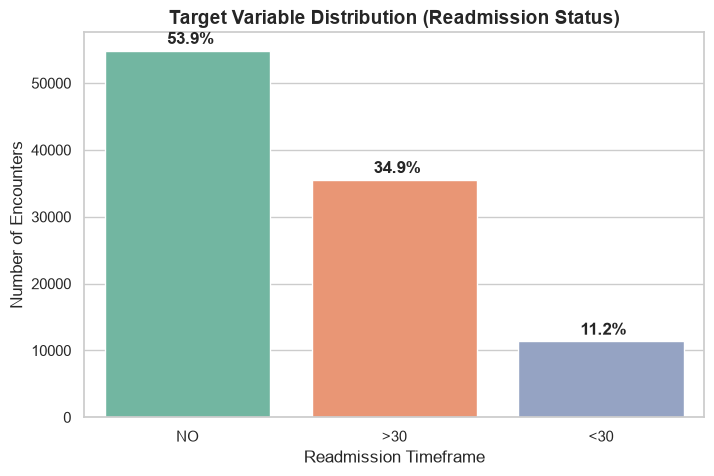

In [4]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], palette="Set2")
plt.title("Target Variable Distribution (Readmission Status)", fontsize=14, fontweight="bold")
plt.xlabel("Readmission Timeframe")
plt.ylabel("Number of Encounters")

# Add percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + 1000
    ax.annotate(percentage, (x, y), size=12, fontweight="bold")

plt.show()